### Media Geometríca y Media Aritmetica 

In [9]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

### Media aritmetica 

In [10]:


S0 = 100
K = 100
sigma = 0.20
r = 0.05
T = 1

mu_G = np.log(S0) + (r - sigma**2 / 2) * T / 2
v_G = sigma**2 * T / 3

d1 = (mu_G + v_G - np.log(K)) / np.sqrt(v_G)
d2 = (mu_G - np.log(K)) / np.sqrt(v_G)

C_G = np.exp(-r*T) * (
    np.exp(mu_G + v_G/2) * norm.cdf(d1)
    - K * norm.cdf(d2)
)

print("Precio de la call geométrica:", C_G)


Precio de la call geométrica: 5.546818633789325


## Simulacion de 10 rutas con MG Y MA

In [15]:

# Parámetros
S0 = 100
K = 100
sigma = 0.20
r = 0.05
T = 1

M = 10       # Número de rutas
n = 252      # Días de negociación

dt = T / n
np.random.seed(42)

# Simular las M rutas de precios
Z = np.random.normal(0, 1, (M, n))

S = np.zeros((M, n + 1))
S[:, 0] = S0

for t in range(n):
    S[:, t+1] = S[:, t] * np.exp(
        (r - sigma**2 / 2) * dt
        + sigma * np.sqrt(dt) * Z[:, t]
    )

# Promedios de las 252 observaciones, excluyendo S0
precios = S[:, 1:]

A_A = np.mean(precios, axis=1)
A_G = np.exp(np.mean(np.log(precios), axis=1))


# Payoffs de las opciones asiáticas
y = np.maximum(A_A - K, 0)  # Call aritmética
x = np.maximum(A_G - K, 0)  # Call geométrica

# Coeficiente beta estimado
EX = np.mean(x)
b = np.cov(y, x, ddof=1)[0, 1] / np.var(x, ddof=1)

# Control Variates
# Reemplaza EX por el precio esperado teórico de la opción geométrica
Y_CV = y - b * (x - precio_geo)

# Precios descontados
precio_MC = np.exp(-r * T) * np.mean(y)
precio_CV = np.exp(-r * T) * np.mean(Y_CV)



### Grafica 

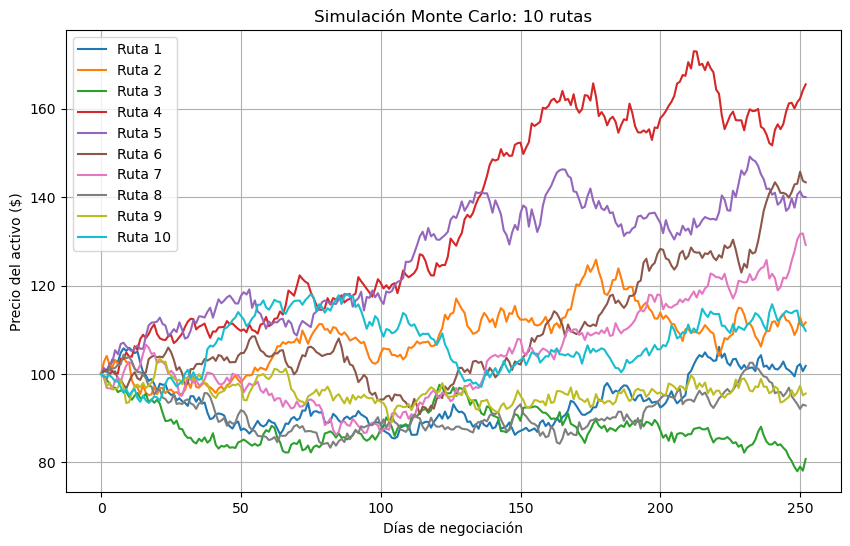

In [16]:


plt.figure(figsize=(10, 6))

for i in range(M):
    plt.plot(range(n + 1), S[i], label=f"Ruta {i+1}")

plt.title("Simulación Monte Carlo: 10 rutas")
plt.xlabel("Días de negociación")
plt.ylabel("Precio del activo ($)")
plt.legend()
plt.grid(True)
plt.show()

### Resultados 

In [17]:
print("Media aritmética por ruta:", A_A)
print("Media geométrica por ruta:", A_G)
print("Beta:", b)

Media aritmética por ruta: [ 93.59996376 108.20345143  88.03230441 135.6059671  126.698689
 109.848834   103.92499739  91.32972069  95.85665816 107.20420538]
Media geométrica por ruta: [ 93.43014721 107.97912016  87.93446242 133.70832345 126.03980846
 109.09500041 103.34011023  91.20687826  95.82809225 107.00810386]
Beta: 1.0439910578516685


## Generar 100 rutas con variable de control de opción asiática geométrica.

Utilizar método visto en clase en ejercicio hecho a mano.

In [18]:
# Parámetros
S0 = 100
K = 100
r = 0.05
sigma = 0.20
T = 1

M = 100       # Número de rutas
n = 252       # Días de negociación
dt = T / n


# 1. Generar variables normales
Z = np.random.normal(0, 1, (M, n))

# 2. Simular las rutas de precios
S = np.zeros((M, n + 1))
S[:, 0] = S0

for t in range(n):
    S[:, t+1] = S[:, t] * np.exp(
        (r - sigma**2 / 2) * dt
        + sigma * np.sqrt(dt) * Z[:, t]
    )

# 3. Promedios aritmético y geométrico
precios = S[:, 1:]

A = np.mean(precios, axis=1)
G = np.exp(np.mean(np.log(precios), axis=1))

# 4. Payoffs de las opciones
Y = np.maximum(A - K, 0)  # Call asiática aritmética
X = np.maximum(G - K, 0)  # Call asiática geométrica

# 5. Descontar los payoffs al presente
Y_desc = np.exp(-r * T) * Y
X_desc = np.exp(-r * T) * X

# 6. Precio teórico de la call asiática geométrica
mu_G = np.log(S0) + (r - sigma**2 / 2) * T * (n + 1) / (2 * n)

var_log_G = (
    sigma**2 * T * (n + 1) * (2*n + 1)
    / (6 * n**2)
)

desv_G = np.sqrt(var_log_G)

d2 = (mu_G - np.log(K)) / desv_G
d1 = d2 + desv_G

precio_geo = np.exp(-r*T) * (
    np.exp(mu_G + var_log_G/2) * norm.cdf(d1)
    - K * norm.cdf(d2)
)

# 7. Calcular beta 
beta = np.cov(Y_desc, X_desc, ddof=1)[0, 1] / np.var(X_desc, ddof=1)

# 8. Precio estimado con variable de control
precio_MC = np.mean(Y_desc)

precio_CV = precio_MC - beta * (
    np.mean(X_desc) - precio_geo
)


# 10. Resultado
print("\n--- RESULTADOS FINALES ---")
print("Precio teórico geométrico:", round(precio_geo, 4))
print("Beta:", round(beta, 4))
print("Precio Monte Carlo aritmético:", round(precio_MC, 4))
print("Precio con variable de control:", round(precio_CV, 4))


--- RESULTADOS FINALES ---
Precio teórico geométrico: 5.5655
Beta: 1.0349
Precio Monte Carlo aritmético: 5.4752
Precio con variable de control: 5.7672


En esta práctica se aplicó el método de variable de control para estimar el precio de una opción call asiática aritmética, utilizando como variable de control una opción asiática geométrica. Se realizaron 100 simulaciones y se obtuvo un precio Monte Carlo de 6.1806, mientras que el precio estimado con variable de control fue de 5.7531. El precio teórico de la opción geométrica fue de 5.5655 y el coeficiente beta estimado fue de 1.034221.